# 1C. FNN - CIFAR10
Single CSV, so we split it ourselves. FNN on RGB caps around 45-50%.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("../datasets/FNN and CNN/CIFAR10/cifar-10.csv")
y = df["label"].to_numpy()
x = df.drop(columns="label").to_numpy()
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)
print(x_train.shape, x_test.shape)

(40000, 3072) (10000, 3072)


In [3]:
model = keras.Sequential([
    layers.Input(shape=(3072,)),
    layers.Rescaling(1./255),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       786,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 789,258 (3.01 MB)

 Trainable params: 789,258 (3.01 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=5)

Epoch 1/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.3201 - loss: 1.9076 - val_accuracy: 0.3739 - val_loss: 1.7710
Epoch 2/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3782 - loss: 1.7434 - val_accuracy: 0.3937 - val_loss: 1.6950
Epoch 3/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4013 - loss: 1.6778 - val_accuracy: 0.3817 - val_loss: 1.7177
Epoch 4/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4133 - loss: 1.6347 - val_accuracy: 0.3967 - val_loss: 1.6798
Epoch 5/5
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4292 - loss: 1.6038 - val_accuracy: 0.4245 - val_loss: 1.6251


In [5]:
loss, acc = model.evaluate(x_test, y_test)
print(f"test loss: {loss:.4f}  test accuracy: {acc:.4f}")

  1/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4375 - loss: 1.5733

 88/313 ━━━━━━━━━━━━━━━━━━━━ 0s 581us/step - accuracy: 0.4354 - loss: 1.5952

171/313 ━━━━━━━━━━━━━━━━━━━━ 0s 594us/step - accuracy: 0.4311 - loss: 1.6064

254/313 ━━━━━━━━━━━━━━━━━━━━ 0s 598us/step - accuracy: 0.4275 - loss: 1.6215

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 619us/step - accuracy: 0.4245 - loss: 1.6251


test loss: 1.6251  test accuracy: 0.4245


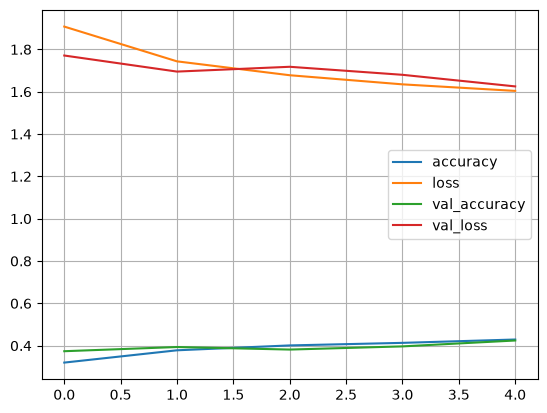

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()